# Lab 7 part 1
## Task 1

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('../data/listings_clean.csv', parse_dates=date_columns)
print(listings.shape)

(4574, 73)


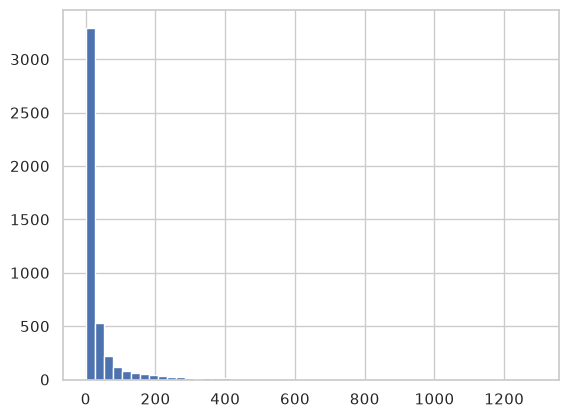

In [4]:
# With matplotlib

fig, ax = plt.subplots()
ax.hist(listings['number_of_reviews'].dropna(), bins=50)
plt.show()

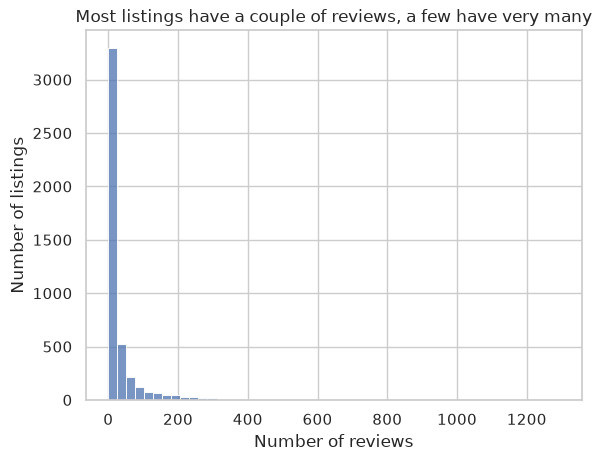

In [7]:
# With seaborn

fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.set_title('Most listings have a couple of reviews, a few have very many')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')

plt.show()

Matplotlib and Seaborn both allow for visualisasing data, but Seaborn has support for example titles and axis labels.

## Task 2

In [9]:
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()

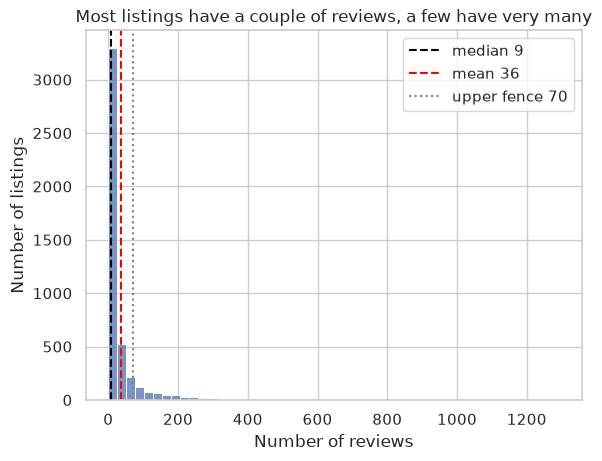

In [11]:
fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.set_title('Most listings have a couple of reviews, a few have very many')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')

ax.axvline(median, color='black', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='red', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='gray', linestyle=':', label=f'upper fence {upper:,.0f}')

ax.legend()

plt.show()

The line that is furthest to the right is the upper fence. The mean is further to the right than the median, due to a few very large values.

## Task 3

In [12]:
listings['reviews_outlier'] = listings['number_of_reviews'] > upper

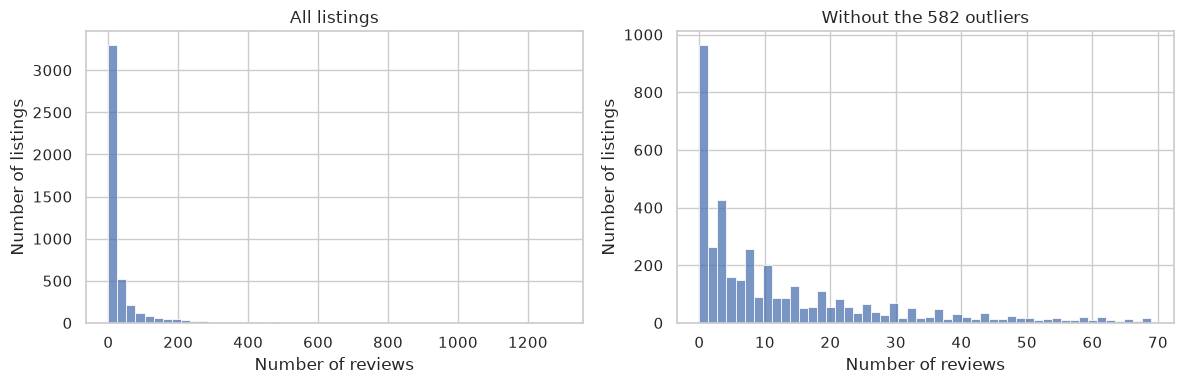

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
sns.histplot(data=listings[~listings['reviews_outlier']], x='number_of_reviews', bins=50, ax=axes[1])

outlier_count = listings['reviews_outlier'].sum()
axes[0].set_title('All listings')
axes[1].set_title(f'Without the {outlier_count} outliers')

for ax in axes:
    ax.set_xlabel('Number of reviews')
    ax.set_ylabel('Number of listings')

plt.tight_layout()

plt.show()

The plot without the outliers shows the distribution of the data with number of reviews between 0 and 70 with much more detail.

## Task 4

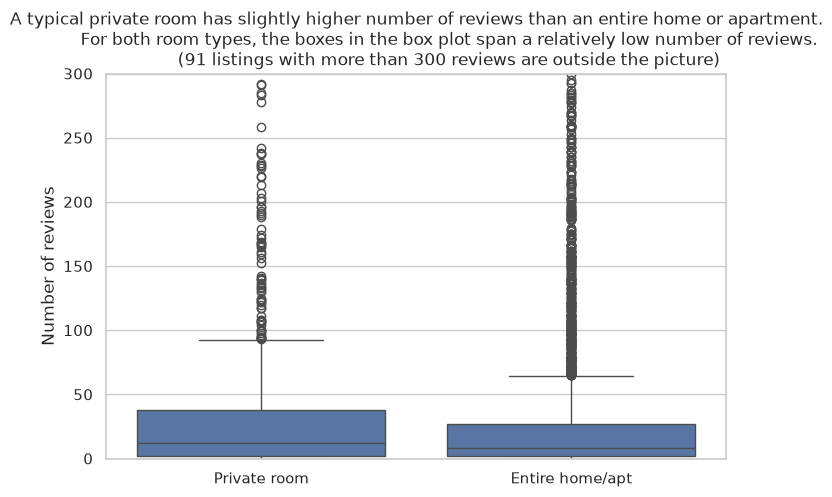

In [30]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=two_types, x='room_type', y='number_of_reviews', ax=ax)

y_limit = 300
count_above_limit = (listings["number_of_reviews"] > y_limit).sum()
ax.set_ylim(0, y_limit)
ax.set_title(f'A typical private room has slightly higher number of reviews than an entire home or apartment.\n\
             For both room types, the boxes in the box plot span a relatively low number of reviews.\n\
             ({count_above_limit} listings with more than {y_limit} reviews are outside the picture)')
ax.set_xlabel('')
ax.set_ylabel('Number of reviews')

plt.show()